In [1]:
import pypsa
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
n0 = pypsa.Network("experiment0.nc")

/Users/davidreynolds/Documents/pers/gridlearn2/.venv/lib/python3.14/site-packages/pypsa/network/io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, generators, lines, loads, sub_networks


In [46]:
# Extract transmission line flows

# flows = n0.lines_t.p0.copy() # p0 mean originating from the bus 0 (for bus 0 -> bus1 line)/ copy so don't modify
# capacities = n0.lines.s_nom

# # # Fraction of each line's capacity being used
# utilization = flows.abs().div(capacities, axis=1)

# tol = 0.001
# binding = utilization >= (1 - tol)
hours = n0.snapshots
mu = n0.lines_t.mu_upper.loc[hours]

# Economically binding constraints
binding = mu.abs() > 0.01

# Recalculate regimes
regimes = binding.apply(
    lambda row: tuple(row.index[row]), axis=1
)

regime_codes, unique_regimes = pd.factorize(regimes)

print(unique_regimes)

Index([                                   (),
                         ('Spring-Raymond',),
                        ('Trenton-Topsham',),
                            ('Gulf-Spring',),
       ('Trenton-Topsham', 'Spring-Raymond'),
       ('Spring-Raymond', 'Topsham-Raymond')],
      dtype='object')


In [47]:
# def get_regime(row):
#     return tuple(row.index[row])

# regimes = binding.apply(get_regime, axis=1)

# Assign each unique regime an integer label
# regime_codes, unique_regimes = pd.factorize(regimes)

y = pd.Series(
    regime_codes,
    index=regimes.index,
    name="regime"
)


In [48]:
print(y.value_counts())

for i, regime in enumerate(unique_regimes):
    print(i, regime)


regime
0    12406
3     1442
1      695
2      462
5       24
4        3
Name: count, dtype: int64
0 ()
1 ('Spring-Raymond',)
2 ('Trenton-Topsham',)
3 ('Gulf-Spring',)
4 ('Trenton-Topsham', 'Spring-Raymond')
5 ('Spring-Raymond', 'Topsham-Raymond')


        count          mean           std           min        max
regime                                                            
0       12406 -1.040671e-15  1.616917e-15 -3.552714e-15   0.000000
1         695 -1.930582e+01  0.000000e+00 -1.930582e+01 -19.305816
2         462  3.266667e+01  0.000000e+00  3.266667e+01  32.666667
3        1442  4.199061e+01  0.000000e+00  4.199061e+01  41.990613
4           3  3.266667e+01  0.000000e+00  3.266667e+01  32.666667
5          24 -1.930582e+01  0.000000e+00 -1.930582e+01 -19.305816


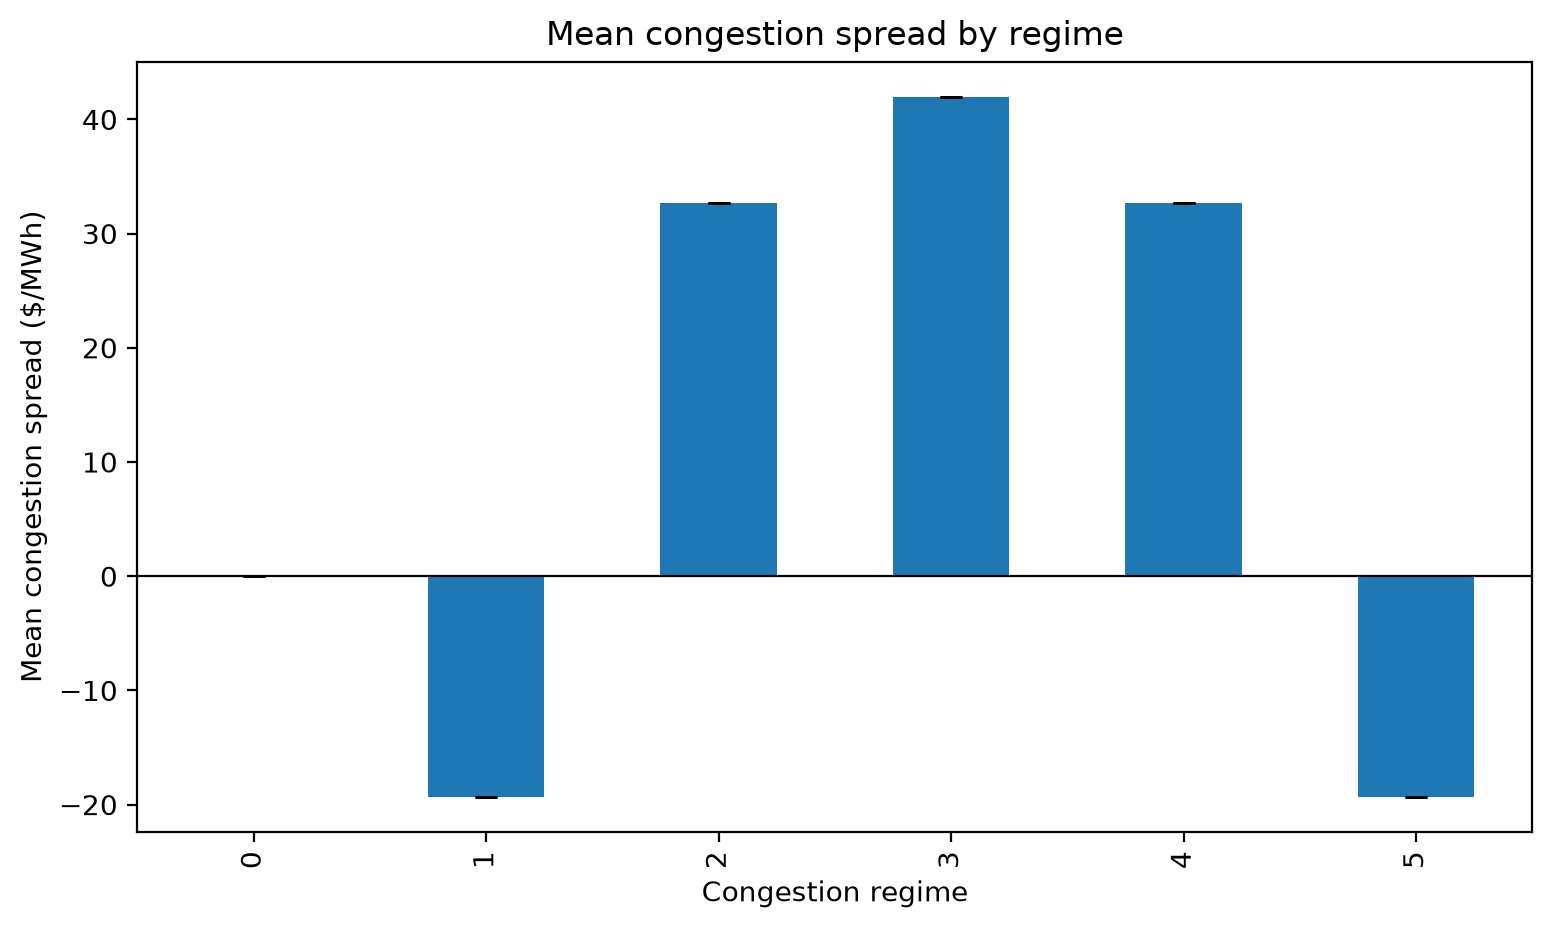

In [49]:
prices = n0.buses_t.marginal_price

spread = prices["Spring"] - prices["Chester"]

results = pd.DataFrame({
    "regime": y,
    "spread": spread
})

summary = (
    results.groupby("regime")["spread"]
    .agg(["count", "mean", "std", "min", "max"])
)

print(summary)

# Standard error of each regime's mean
se = summary["std"] / np.sqrt(summary["count"])

ax = summary["mean"].plot.bar(
    yerr=1.96 * se,
    capsize=4,
    figsize=(9, 5)
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Congestion regime")
ax.set_ylabel("Mean congestion spread ($/MWh)")
ax.set_title("Mean congestion spread by regime")
plt.show()



In [14]:
# Frequency of distinct congestion spreads
results["spread"].round(3).value_counts().sort_index()

spread
-19.306      719
 0.000     12406
 32.667      465
 41.991     1442
Name: count, dtype: int64

In [16]:
pd.crosstab(
    results["regime"],
    results["spread"].round(3)
)


for code, lines in enumerate(unique_regimes):
    print(f"Regime {code}: {lines}")

Regime 0: ()
Regime 1: ('Spring-Raymond',)
Regime 2: ('Trenton-Topsham',)
Regime 3: ('Gulf-Spring',)
Regime 4: ('Trenton-Topsham', 'Gulf-Spring')
Regime 5: ('Trenton-Topsham', 'Spring-Raymond')
Regime 6: ('Spring-Raymond', 'Topsham-Raymond')


In [19]:
# I'd examine the shadow prices specifically for regime 4, where both North–South ties bind.

cols = ["Trenton-Topsham", "Gulf-Spring"]

pd.DataFrame({
    "spread": results["spread"],
    "mu_TT": n0.lines_t.mu_upper.loc[hours, cols[0]],
    "mu_GS": n0.lines_t.mu_upper.loc[hours, cols[1]],
    "regime": y
}).query("regime == 4").round(3)

NameError: name 'hours' is not defined

In [41]:
y = pd.Series(
    regime_codes,
    index=regimes.index,
    name="regime"
)

spread = results["spread"]

cols = ["Trenton-Topsham", "Gulf-Spring"]

regime4 = y[y == 4].index

result = pd.DataFrame({
    "spread": spread.reindex(regime4),
    "TT_upper": n0.lines_t.mu_upper[
        cols[0]
    ].reindex(regime4),
    "GS_upper": n0.lines_t.mu_upper[
        cols[1]
    ].reindex(regime4),
})

print(result.round(3))

                     spread  TT_upper  GS_upper
snapshot                                       
2025-01-29 04:00:00  32.667   -69.127    -0.000
2025-03-22 05:00:00  41.991    -0.000   -79.612
2025-05-10 02:00:00  41.991    -0.000   -79.612
2025-06-06 18:00:00  32.667   -69.127    -0.000
2025-06-13 22:00:00  32.667   -69.127    -0.000
2025-06-22 20:00:00  41.991    -0.000   -79.612
2025-07-18 05:00:00  41.991    -0.000   -79.612
2025-12-05 19:00:00  41.991    -0.000   -79.612
2025-12-18 21:00:00  41.991    -0.000   -79.612
2026-02-20 01:00:00  41.991    -0.000   -79.612
2026-03-02 21:00:00  32.667   -69.127    -0.000
2026-03-11 15:00:00  41.991    -0.000   -79.612
2026-06-18 03:00:00  32.667   -69.127    -0.000
2026-06-26 12:00:00  32.667   -69.127    -0.000
2026-07-28 22:00:00  41.991    -0.000   -79.612


In [ ]:
print(n0.lines_t.p0.loc[regime4, cols].round(2))

print(n0.lines.loc[cols, "s_nom"])bindin

name                 Trenton-Topsham  Gulf-Spring
snapshot                                         
2025-01-29 04:00:00            60.00        47.95
2025-03-22 05:00:00            59.96        48.00
2025-05-10 02:00:00            59.96        48.00
2025-06-06 18:00:00            60.00        47.99
2025-06-13 22:00:00            60.00        47.97
2025-06-22 20:00:00            59.94        48.00
2025-07-18 05:00:00            59.95        48.00
2025-12-05 19:00:00            59.96        48.00
2025-12-18 21:00:00            59.95        48.00
2026-02-20 01:00:00            59.98        48.00
2026-03-02 21:00:00            60.00        47.97
2026-03-11 15:00:00            59.94        48.00
2026-06-18 03:00:00            60.00        47.98
2026-06-26 12:00:00            60.00        47.97
2026-07-28 22:00:00            59.97        48.00
name
Trenton-Topsham    60.0
Gulf-Spring        48.0
Name: s_nom, dtype: float64


In [40]:
print("Upper:", n0.lines_t.mu_upper.columns.tolist())
print("Lower:", n0.lines_t.mu_lower.columns.tolist())

Upper: ['Chester-Trenton', 'Chester-Gulf', 'Trenton-Gulf', 'Trenton-Topsham', 'Gulf-Spring', 'Spring-Topsham', 'Spring-Raymond', 'Topsham-Raymond']
Lower: []


In [33]:
n0.lines_t.mu_upper["Trenton-Topsham"].reindex(regime4)

snapshot
2025-01-29 04:00:00   -69.126984
2025-03-22 05:00:00    -0.000000
2025-05-10 02:00:00    -0.000000
2025-06-06 18:00:00   -69.126984
2025-06-13 22:00:00   -69.126984
2025-06-22 20:00:00    -0.000000
2025-07-18 05:00:00    -0.000000
2025-12-05 19:00:00    -0.000000
2025-12-18 21:00:00    -0.000000
2026-02-20 01:00:00    -0.000000
2026-03-02 21:00:00   -69.126984
2026-03-11 15:00:00    -0.000000
2026-06-18 03:00:00   -69.126984
2026-06-26 12:00:00   -69.126984
2026-07-28 22:00:00    -0.000000
Name: Trenton-Topsham, dtype: float64